## Part 1: Implementation of the Barabási-Albert Model

### 1.2. Implementation from Scratch

In [1]:
import networkx as nx
import numpy as np

def ba_model_scratch(n, m, m0 = 5):
    g = nx.complete_graph(m0)
    # for each new node
    for new_node in range(m0, n):
        # calculate attachment probabilities
        degrees = np.array([d for _, d in g.degree()])
        total_degrees = degrees.sum()
        probs = degrees / total_degrees

        # select m existing nodes based on probabilities
        targets = np.random.choice(g.nodes(), m, replace=False,p=probs)

        # add new node and links
        for t in targets:
            g.add_edge(new_node, t)
    
    return g

In [2]:
# example usage
n = 50
m = 5
m0 = 5
g = ba_model_scratch(n, m, m0)

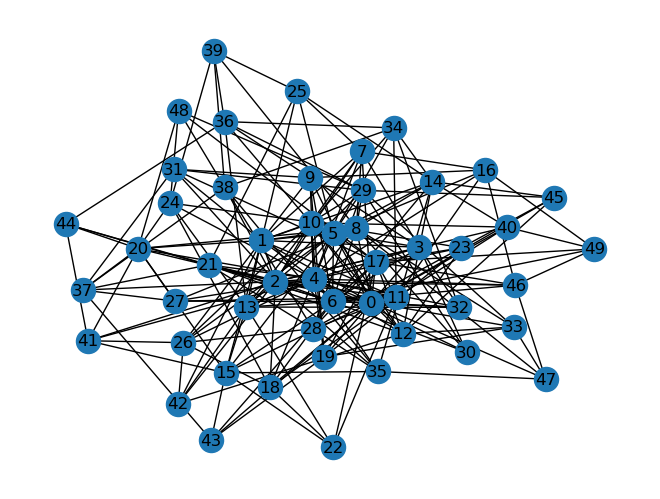

In [3]:
nx.draw(g, with_labels=True)

In [4]:
import matplotlib.pyplot as plt

def visualize_ba_network(G, n_nodes=100, node_scale=80, layout_seed=42):
    """
    Visualize a subset of a Barabási–Albert (BA) network.

    Parameters
    ----------
    G : networkx.Graph
        The BA graph to visualize.
    n_nodes : int, optional
        Number of nodes (starting from 0) to visualize. Default is 100.
    node_scale : float, optional
        Scale factor for node sizes based on degree. Default is 30.
    layout_seed : int, optional
        Random seed for reproducible layout positioning. Default is 42.
    """
    
    # Select subset of nodes
    sub_nodes = list(range(min(n_nodes, len(G))))
    H = G.subgraph(sub_nodes)
    
    # Node degrees → control node size
    degrees = dict(H.degree())
    node_sizes = [v * node_scale for v in degrees.values()]
    
    # Layout and drawing
    pos = nx.spring_layout(H, seed=layout_seed)
    
    plt.figure(figsize=(10, 8))
    nx.draw(
        H,
        pos,
        with_labels=False,
        node_size=node_sizes,
        node_color='skyblue',
        edge_color='gray',
        alpha=0.7
    )
    
    plt.title(f"First {len(sub_nodes)} Nodes of BA Network (Node Size ∝ Degree)")
    plt.show()


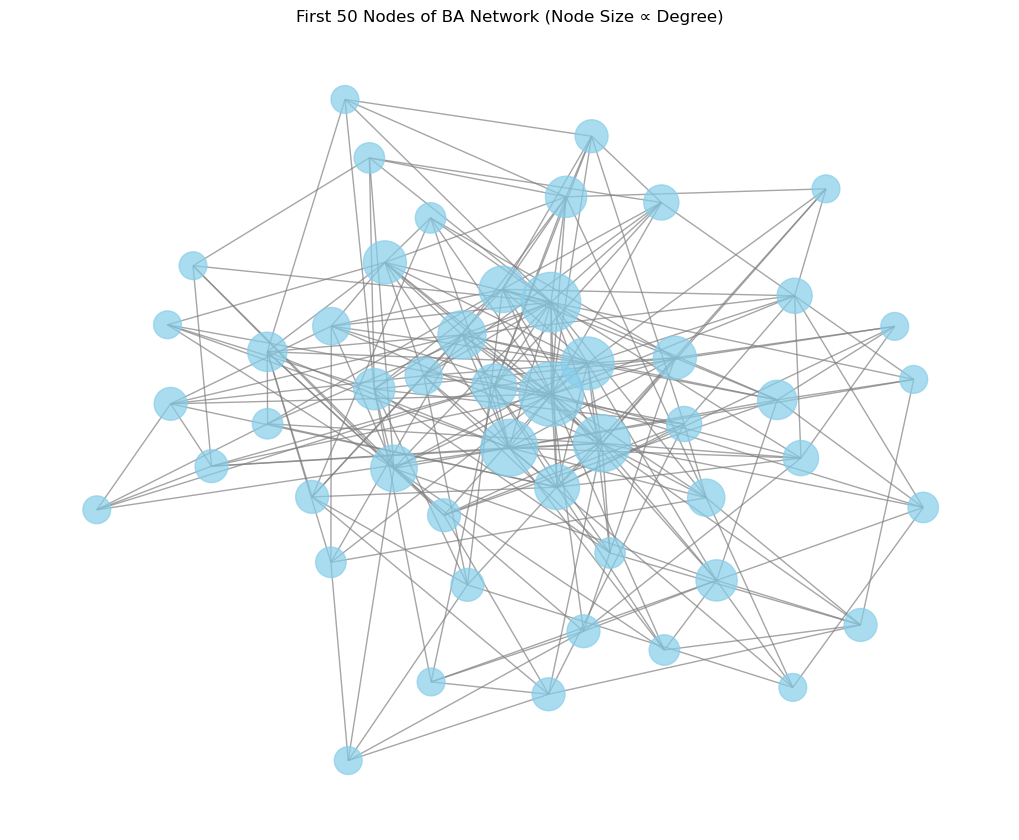

In [5]:
visualize_ba_network(g)

### 1.3. Implementation using NetworkX

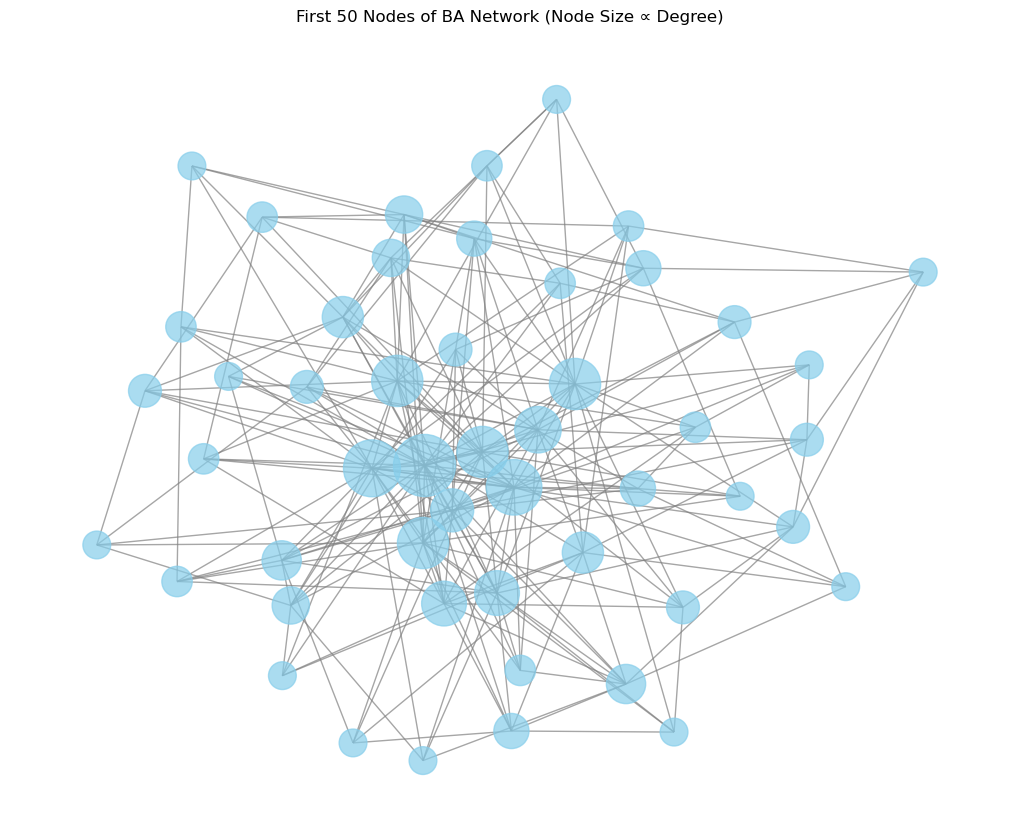

In [6]:
g_from_implementation = nx.barabasi_albert_graph(n, m)
visualize_ba_network(g_from_implementation)

The results from both implementations are pretty similar at least visually with the parameters used.

## Part 2: Empirical Analysis of the BA Mode

In [7]:
n = 10000
m = 2
g = ba_model_scratch(n, m)


### 2.1. Visualizing the Network

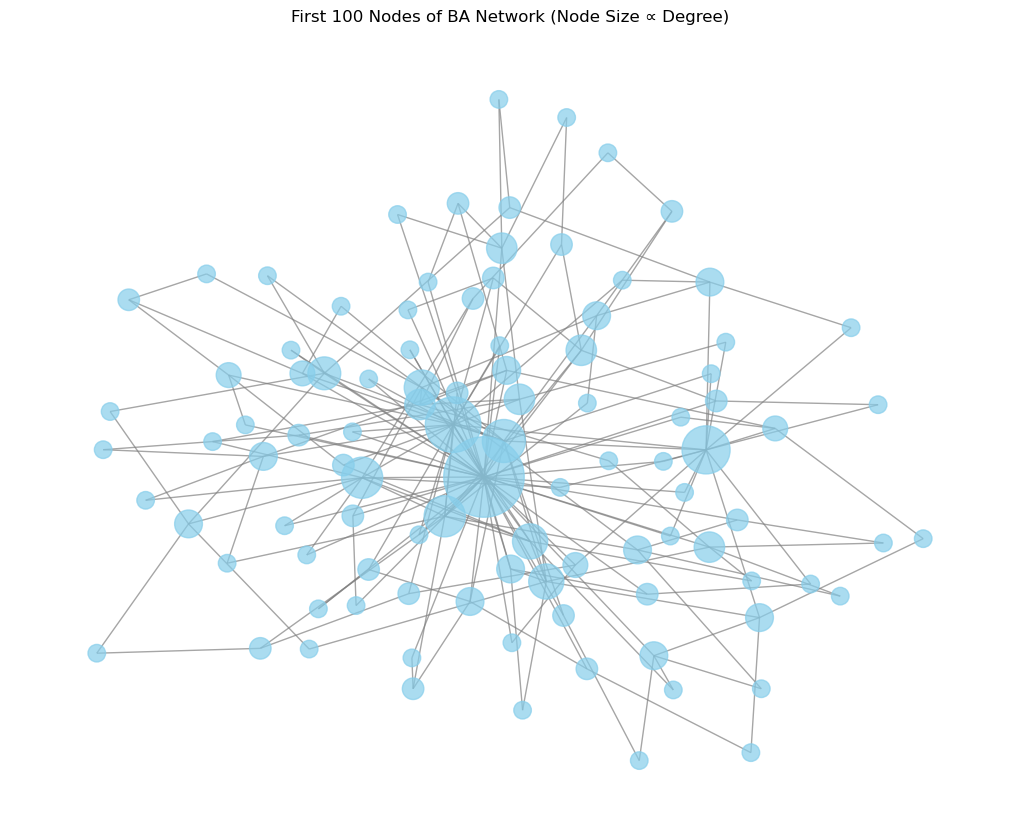

In [8]:
visualize_ba_network(g)

We can indeed observe the presence of a few high degree hubs in the center of the network. The m0 for the scratch implementation is set to 5 by default, the distribution of the high degree hubs will change slightly with variations of that parameter. 

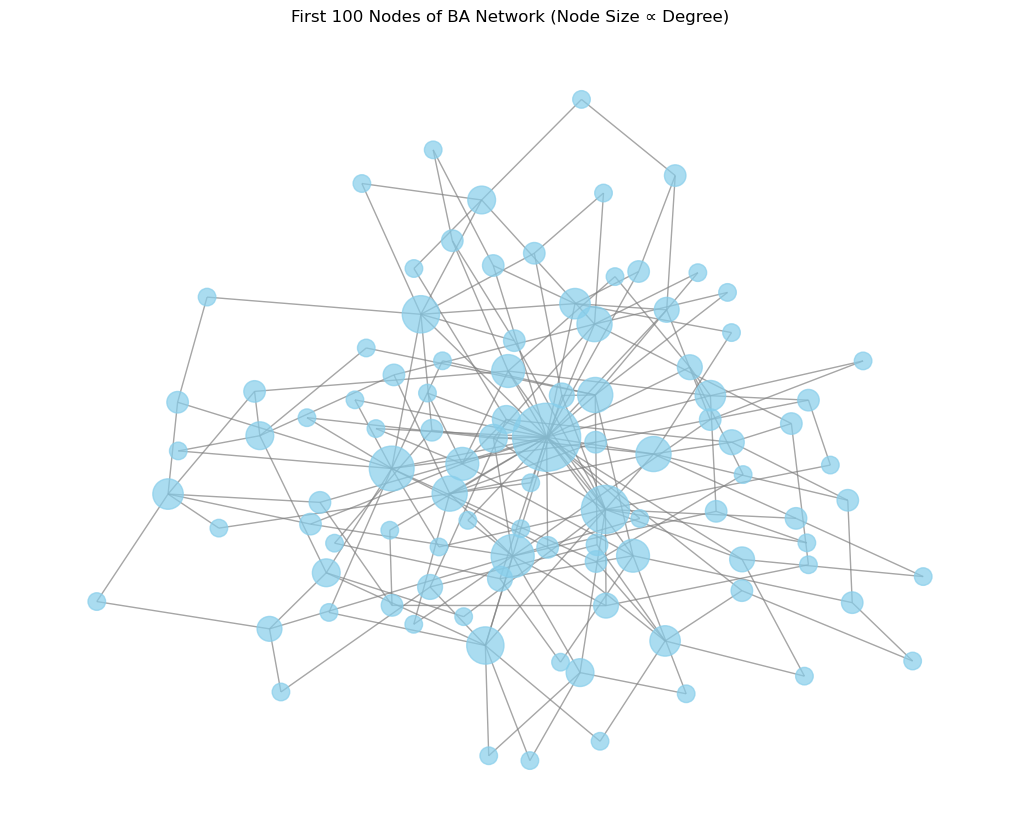

In [9]:
g_pro = nx.barabasi_albert_graph(n, m)
visualize_ba_network(g_pro)

With the default implementation from networkX there is less of a difference between the high degree hubs and the normal nodes, probably because the original connected graph has a higher number of nodes. But we can still observe a few highly connected nodes in the center of the graph.

For the purpose of analysis and this practice I will analyze the graph created with my own implementation because the differences are more notable.

### 2.2. Analyzing the Degree Distribution

In [10]:
# degree for each node
degrees = np.array([d for _, d in g.degree()], dtype=float)  


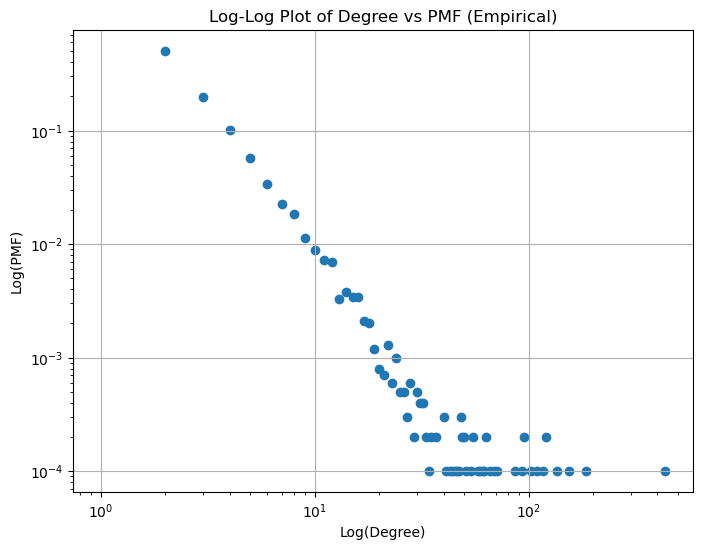

In [11]:
# Probability Mass Function (PMF)
degree_counts = np.bincount(degrees.astype(int))
ks = np.arange(len(degree_counts), dtype=float)  
pmf = degree_counts / degree_counts.sum()

# Log-Log Plot of PMF
plt.figure(figsize=(8, 6))
plt.scatter(ks, pmf)
plt.xlabel('Log(Degree)')
plt.ylabel('Log(PMF)')
plt.xscale('log')
plt.yscale('log')
plt.title('Log-Log Plot of Degree vs PMF (Empirical)')
plt.grid(True)
plt.show()

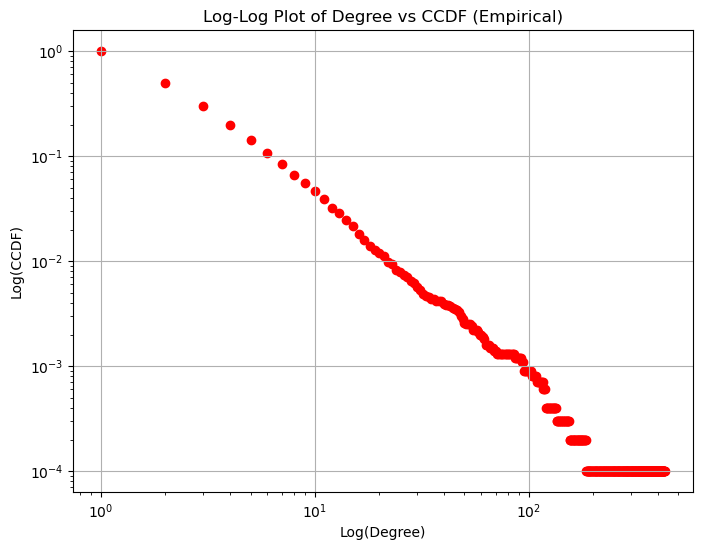

In [ ]:
# Complementary Cumulative Distribution Function
ccdf = 1 - np.cumsum(pmf)
mask = (ccdf > 1e-8) # to avoid log(0)

# Log-Log Plot of PMF
plt.figure(figsize=(8, 6))
plt.scatter(ks[mask], ccdf[mask], color='red')
plt.xlabel('Log(Degree)')
plt.ylabel('Log(CCDF)')
plt.xscale('log')
plt.yscale('log')
plt.title('Log-Log Plot of Degree vs CCDF (Empirical)')
plt.grid(True)
plt.show()

Yes, both middle parts of the plot appear linear on the log-log scale.

### 2.3. Estimating the Power-Law Exponent (γ)

#### Method 1: Linear Regression on the CCDF

In [ ]:
k_min = 5     
tail_mask = ks >= k_min

k_tail = ks[tail_mask]
ccdf_tail = ccdf[tail_mask]

In [21]:
# log10 or natural log both work; just be consistent
x = np.log10(k_tail)
y = np.log10(ccdf_tail)

# linear regression: y = alpha * x + beta
alpha, beta = np.polyfit(x, y, 1)

gamma = 1 - alpha

print(f"slope alpha = {alpha:.4f}")
print(f"estimated gamma = {gamma:.4f}")


slope alpha = -1.7989
estimated gamma = 2.7989


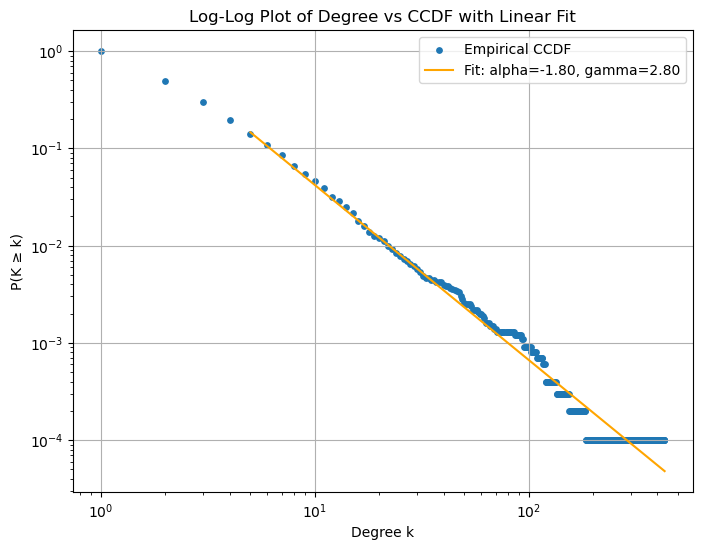

In [24]:
plt.figure(figsize=(8, 6))
plt.scatter(ks[mask], ccdf[mask], s=15, label='Empirical CCDF')

# fitted line over the tail
x_fit = np.linspace(x.min(), x.max(), 100)
y_fit = alpha * x_fit + beta
plt.plot(10**x_fit, 10**y_fit, label=f'Fit: alpha={alpha:.2f}, gamma={gamma:.2f}', color='orange')

plt.xscale('log')
plt.yscale('log')
plt.xlabel("Degree k")
plt.ylabel("P(K ≥ k)")
plt.title("Log-Log Plot of Degree vs CCDF with Linear Fit")
plt.grid(True)
plt.legend()
plt.show()


### Method 2: Using the powerlaw Python Library

In [27]:
import powerlaw

fit = powerlaw.Fit(degrees, discrete=True, verbose=False)

gamma_powerlaw = fit.power_law.alpha      # this is γ
xmin_powerlaw = fit.power_law.xmin       # fitted lower cutoff

print(f"powerlaw estimate: γ = {gamma_powerlaw:.3f}")
print(f"fitted xmin = {xmin_powerlaw}")

powerlaw estimate: γ = 2.683
fitted xmin = 4.0


The manual estimate was 2.79 and the powerlaw estimate was 2.68, and the theoretical value of gamma is 3 so even though it's not a perfect fit it's pretty similar.

## Part 3: Validation with a Real-World Network

### 3.1. Dataset and Preprocessing

In [29]:
import networkx as nx

# Path to your uploaded file
path = "CA-GrQc.txt"

# Create an undirected graph
G = nx.Graph()

# Read the edges
with open(path, "r") as f:
    for line in f:
        # skip comments
        if line.startswith("#"):
            continue

        # parse edge
        parts = line.strip().split()
        if len(parts) == 2:
            u, v = map(int, parts)
            G.add_edge(u, v)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())


Number of nodes: 5242
Number of edges: 14496


### 3.2. Comparative Analysis

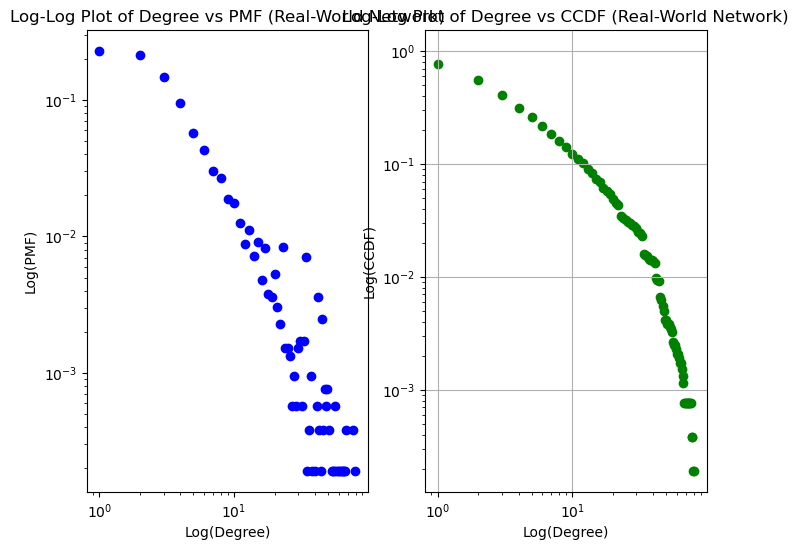

In [32]:
# PMF and CCDF for the real-world network
degrees = np.array([d for _, d in G.degree()], dtype=float) 
degree_counts = np.bincount(degrees.astype(int))
ks = np.arange(len(degree_counts), dtype=float)
pmf = degree_counts / degree_counts.sum()
ccdf = 1 - np.cumsum(pmf)
mask = (ccdf > 1e-8) # to avoid log(0)
fig, axs = plt.subplots(figsize=(8, 6), nrows=1, ncols=2)
axs[0].scatter(ks[mask], pmf[mask], color='blue')
axs[0].set_xlabel('Log(Degree)')
axs[0].set_ylabel('Log(PMF)')
axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].set_title('Log-Log Plot of Degree vs PMF (Real-World Network)')
axs[1].scatter(ks[mask], ccdf[mask], color='green')
axs[1].set_xlabel('Log(Degree)')
axs[1].set_ylabel('Log(CCDF)')
axs[1].set_xscale('log')
axs[1].set_yscale('log')
axs[1].set_title('Log-Log Plot of Degree vs CCDF (Real-World Network)')
axs[1].grid(True)
plt.show()

In [33]:
# Estimate gamma for the real-world network with the powerlaw library
fit_real = powerlaw.Fit(degrees, discrete=True, verbose=False)
gamma_real = fit_real.power_law.alpha
xmin_real = fit_real.power_law.xmin
print(f"Real-world network estimate: γ = {gamma_real:.3f}")
print(f"Fitted xmin = {xmin_real}")

Real-world network estimate: γ = 2.089
Fitted xmin = 3.0


My model had a higher gamma than the estimated one for the real world network, which is closer to 2.

### Questions

1. Does the degree distribution of the Citation network follow a power-law? Over
what range (xmin)?

Yes, it follows a power law of gamma=2.09 approxiamtely when the degrees are k>= 3.

2. How does the estimated γ for the Citation network compare to the theoretical
value from the BA model? What might account for any differences?

The BA model predicts γ=3, but we observe γ≈2.09, indicating a heavier-tailed distribution than the BA model. This discrepancy likely arises because the real Citation network includes additional mechanisms such as heterogeneous node “fitness”, aging, and more complex attachment rules that are not captured by the basic BA model.

3. The BA model incorporates only growth and preferential attachment. What are
some real-world social processes that these mechanisms might represent?
What important social processes are missing from this simple model? (e.g.,
homophily, aging of nodes, external events).

Growth and preferential attachment in the BA model correspond to new actors entering the system and tending to connect to already popular or highly visible nodes (e.g., citing highly cited papers, collaborating with well-known authors). However, real social and citation networks also exhibit homophily, node aging, heterogeneous “fitness” or quality, triadic closure, and the influence of external events. These additional mechanisms are not captured by the simple BA model, and they likely contribute to the differences between the empirical exponent γ≈2.09 and the theoretical BA value of 3.